In [19]:
import pandas as pd
import numpy as np

In [20]:
data = pd.read_csv("tips_data.csv")
data

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,NaN,1.66,Male,No,Sun,NaN,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,NaN,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [21]:
# selecting only numerical column--
df = data[["total_bill","tip","size"]]
df

,total_bill,tip,size
0,16.99,1.01,2
1,NaN,1.66,3
2,21.01,3.50,3
3,23.68,3.31,2
4,24.59,3.61,4
...,...,...,...
239,29.03,5.92,3
240,27.18,2.00,2
241,22.67,2.00,2
242,17.82,1.75,2


In [22]:
# Scaling the values--
from sklearn.preprocessing import MinMaxScaler
import numpy as np

In [23]:
scaler = MinMaxScaler()
val = scaler.fit_transform(df)
val = np.round(val,2)
val
dff = pd.DataFrame(val , columns=["total_bill","tip","size"])
dff

,total_bill,tip,size
0,0.29,0.00,0.2
1,NaN,0.07,0.4
2,0.38,0.28,0.4
3,0.43,0.26,0.2
4,0.45,0.29,0.6
...,...,...,...
239,0.54,0.55,0.4
240,0.51,0.11,0.2
241,0.41,0.11,0.2
242,0.31,0.08,0.2


In [24]:
from sklearn.cluster import KMeans

In [25]:
df.head()
dff = df.dropna()
km = KMeans(n_clusters=3 , random_state=40)
km.fit_predict(dff)

array([0, 2, 2, 2, 2, 0, 2, 0, 0, 0, 1, 0, 2, 0, 2, 0, 0, 0, 2, 2, 2, 0,
       1, 2, 2, 0, 0, 2, 2, 0, 2, 0, 2, 2, 2, 0, 0, 2, 1, 0, 0, 0, 0, 1,
       2, 2, 1, 2, 2, 0, 0, 1, 0, 2, 2, 1, 2, 0, 1, 2, 0, 0, 2, 0, 2, 0,
       0, 2, 0, 0, 0, 2, 2, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 0, 1, 0, 2, 2,
       2, 2, 2, 0, 0, 2, 1, 2, 0, 2, 0, 0, 0, 1, 2, 2, 0, 2, 2, 2, 0, 0,
       0, 1, 2, 2, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 1, 0, 0, 0, 2, 2, 2, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 1, 1, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 2, 2,
       1, 1, 2, 0, 0, 2, 0, 0, 0, 0, 2, 2, 1, 0, 0, 1, 0, 0, 1, 0, 1, 2,
       0, 0, 1, 1, 2, 1, 2, 1, 2, 2, 1, 2, 2, 0, 2, 2, 0, 0, 0, 0, 1, 0,
       0, 2, 0, 0, 0, 2, 0, 2, 1, 2, 0, 1, 2, 1, 0, 2, 0, 2, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 1, 1, 2, 2, 2, 0,
       2], dtype=int32)

In [26]:
sse_data = []
for i in range(1,14):
    km = KMeans(n_clusters=i, random_state=40)
    km.fit_predict(dff)
    sse_data.append(km.inertia_)
np.round(sse_data,3)

array([19851.915,  6887.807,  3752.681,  2273.543,  1603.733,  1297.231,
        1056.141,   907.349,   777.011,   678.548,   642.53 ,   600.759,
         542.576])

In [27]:
import matplotlib.pyplot as plt

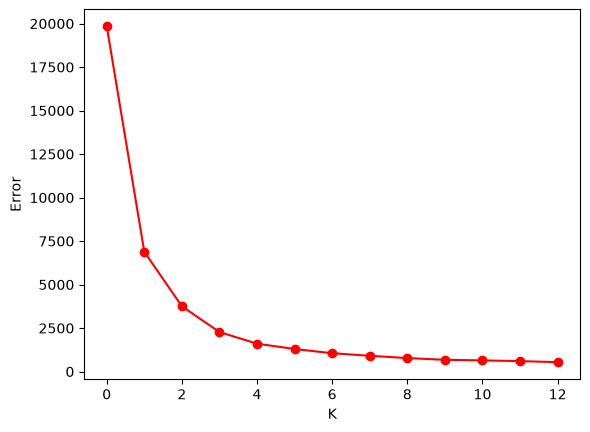

In [28]:
# Making graph--
plt.Figure(figsize=(8,6))
plt.plot(sse_data,marker = "o",color="red")
plt.xlabel("K")
plt.ylabel("Error")
plt.show()